In [ ]:
!git clone https://github.com/mateenyaqoob/unstructuredata_tfidf_repo.git

Cloning into 'unstructuredata_tfidf_repo'...
remote: Enumerating objects: 106, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 106 (delta 26), reused 16 (delta 15), pack-reused 62 (from 1)
Receiving objects: 100% (106/106), 46.56 KiB | 1.66 MiB/s, done.
Resolving deltas: 100% (34/34), done.


In [ ]:
"""Utilities for loading the classroom dataset."""
import sys
import os
from typing import List, Tuple

# Dynamic path discovery inside /content
repo_path = '/content/unstructuredata_tfidf_repo'
if os.path.exists(repo_path):
    if repo_path not in sys.path:
        sys.path.append(repo_path)
    # Also try adding inner directories if they exist
    inner_src = os.path.join(repo_path, 'src')
    if os.path.exists(inner_src) and inner_src not in sys.path:
        sys.path.append(inner_src)

try:
    # Attempt multiple structures depending on repository design
    from data.documents import TITLES, DOCUMENTS
except ModuleNotFoundError:
    try:
        from unstructuredata_tfidf_repo.data.documents import TITLES, DOCUMENTS
    except ModuleNotFoundError:
        try:
            from src.data.documents import TITLES, DOCUMENTS
        except ModuleNotFoundError:
            # Backup definition to ensure the notebook runs seamlessly
            TITLES = [
                "AI in Healthcare",
                "Climate Change",
                "Basketball Strategy",
                "Italian Pasta",
                "Space Exploration",
                "Cybersecurity",
                "Music Theory",
                "Gardening Vegetables",
                "Economics Inflation",
                "Public Health"
            ]
            DOCUMENTS = [
                "Artificial intelligence is transforming healthcare with advanced diagnosis algorithms and patient care automation.",
                "Climate change driven by carbon emissions and fossil fuel burning accelerates global warming and impacts ecosystems.",
                "Modern basketball defense strategies focus on high pressure switching and pick and roll recovery situations.",
                "Authentic Italian pasta relies on bronze die extrusion, fresh eggs, and rich traditional sauces like carbonara.",
                "Space exploration agencies aim to land manned spacecraft on Mars within the next decade using advanced rockets.",
                "Robust cybersecurity requires defensive vigilance against network intrusion, social engineering, and system exploits.",
                "Music theory provides deep insight into modal scales, key signatures, and rhythmic patterns for composers.",
                "Organic vegetable gardening improves soil health through systematic crop rotation and natural pest control.",
                "Macroeconomic inflation occurs when money supply grows excessively relative to real economic productivity and output.",
                "Community public health campaigns successfully promote adequate sleep, active exercise, and balanced nutrition."
            ]


def load_documents() -> Tuple[List[str], List[str]]:
    """Return (titles, documents)."""
    return TITLES, DOCUMENTS


if __name__ == "__main__":
    titles, docs = load_documents()
    print(f"Loaded {len(docs)} documents.")
    for t, d in zip(titles, docs):
        print(f"- {t}: {len(d.split())} words")

Loaded 10 documents.
- AI in Healthcare: 85 words
- Climate Change: 83 words
- Basketball Strategy: 85 words
- Italian Pasta: 91 words
- Space Exploration: 86 words
- Cybersecurity: 88 words
- Music Theory: 87 words
- Gardening Vegetables: 89 words
- Economics Inflation: 89 words
- Public Health: 91 words


In [ ]:
"""Reusable TF-IDF helpers for the class activity."""
from typing import List, Tuple

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def build_tfidf(
    documents: List[str],
    stop_words: str = "english",
    ngram_range: Tuple[int, int] = (1, 1),
    max_df: float = 1.0,
    min_df: int = 1,
):
    """Fit a TfidfVectorizer and return (vectorizer, matrix)."""
    vectorizer = TfidfVectorizer(
        stop_words=stop_words,
        ngram_range=ngram_range,
        max_df=max_df,
        min_df=min_df,
    )
    matrix = vectorizer.fit_transform(documents)
    return vectorizer, matrix


def to_dataframe(matrix, vectorizer, titles: List[str]) -> pd.DataFrame:
    """Convert a sparse TF-IDF matrix into a labeled DataFrame."""
    return pd.DataFrame(
        matrix.toarray(),
        columns=vectorizer.get_feature_names_out(),
        index=titles,
    )


def top_terms_per_document(df: pd.DataFrame, n: int = 5) -> dict:
    """Return {title: {term: score}} of the top-n TF-IDF terms per document."""
    result = {}
    for title in df.index:
        top = df.loc[title].sort_values(ascending=False).head(n)
        result[title] = top.to_dict()
    return result


def rank_documents_for_query(
    query: str,
    vectorizer: TfidfVectorizer,
    matrix,
    titles: List[str],
) -> List[Tuple[str, float]]:
    """Return [(title, similarity_score)] sorted by cosine similarity (desc)."""
    query_vec = vectorizer.transform([query])
    scores = cosine_similarity(query_vec, matrix).flatten()
    return sorted(zip(titles, scores), key=lambda x: x[1], reverse=True)

In [ ]:
"""End-to-end walkthrough of the TF-IDF 30-minute class activity."""

# The helper functions are already defined in the preceding cells of this notebook,
# so we do not need to import them from a 'src' package.


def main() -> None:
    titles, documents = load_documents()
    print(f"Loaded {len(documents)} documents.\n")

    # 1) Build TF-IDF matrix
    vectorizer, matrix = build_tfidf(documents)
    print("TF-IDF matrix shape:", matrix.shape)

    df = to_dataframe(matrix, vectorizer, titles)
    print("\nSample of the TF-IDF matrix:")
    print(df.iloc[:3, :10].round(3))

    # 2) Top terms per document
    print("\n=== Top 5 TF-IDF terms per document ===")
    for title, terms in top_terms_per_document(df, n=5).items():
        joined = ", ".join(f" {k}({v:.2f})" for k, v in terms.items())
        print(f"\n{title}:\n  {joined}")

    # 3) Query similarity challenge
    queries = [
        "renewable energy and climate policy",
        "password security and phishing",
        "healthy sleep exercise and diet",
    ]
    for q in queries:
        print(f"\n=== Query: {q!r} ===")
        for title, score in rank_documents_for_query(q, vectorizer, matrix, titles):
            print(f"  {title:25s} {score:.3f}")


if __name__ == "__main__":
    main()

Loaded 10 documents.

TF-IDF matrix shape: (10, 537)

Sample of the TF-IDF matrix:
                     ability  accelerate  access  accountability  accuracy  \
AI in Healthcare        0.00         0.0     0.0           0.125     0.125   
Climate Change          0.00         0.0     0.0           0.000     0.000   
Basketball Strategy     0.13         0.0     0.0           0.000     0.000   

                     accurate  actions  activity  adaptation  add  
AI in Healthcare        0.000    0.000       0.0       0.000  0.0  
Climate Change          0.125    0.125       0.0       0.125  0.0  
Basketball Strategy     0.000    0.000       0.0       0.000  0.0  

=== Top 5 TF-IDF terms per document ===

AI in Healthcare:
   ai(0.37),  healthcare(0.25),  use(0.16),  waiting(0.12),  transforming(0.12)

Climate Change:
   change(0.25),  emissions(0.25),  energy(0.21),  climate(0.21),  burning(0.12)

Basketball Strategy:
   decide(0.13),  switch(0.13),  player(0.13),  situations(0.13),  pick(

### Step 5: Optional Challenge

Let's re-run the vectorizer using additional parameters:
* `ngram_range=(1, 2)` (to include unigrams and bigrams)
* `max_df=0.8` (ignore terms that appear in more than 80% of the documents)
* `min_df=2` (ignore terms that appear in fewer than 2 documents)

We will compare the resulting vocabulary size and top terms against our previous model.

In [ ]:
# Ensure we have the definitions loaded
titles, documents = load_documents()

# Fit the vectorizer with new challenge parameters
vectorizer_opt, matrix_opt = build_tfidf(
    documents,
    stop_words="english",
    ngram_range=(1, 2),
    max_df=0.8,
    min_df=2
)

print("=== Optional Challenge TF-IDF Matrix ===")
print("New Matrix Shape:", matrix_opt.shape)
print("New Vocabulary Size:", len(vectorizer_opt.vocabulary_))

# Convert to DataFrame to inspect
df_opt = to_dataframe(matrix_opt, vectorizer_opt, titles)

# Inspect top 5 terms per document under the new parameters
print("\n=== Top 5 TF-IDF terms per document (Optional Challenge) ===")
for title, terms in top_terms_per_document(df_opt, n=5).items():
    joined = ", ".join(f"{k}({v:.2f})" for k, v in terms.items() if v > 0)
    if joined:
        print(f"{title}: {joined}")
    else:
        print(f"{title}: No terms met the min_df/max_df criteria!")

=== Optional Challenge TF-IDF Matrix ===
New Matrix Shape: (10, 69)
New Vocabulary Size: 69

=== Top 5 TF-IDF terms per document (Optional Challenge) ===
AI in Healthcare: use(0.39), clean(0.25), intelligence(0.25), disease(0.25), careful(0.25)
Climate Change: climate(0.39), energy(0.39), governments(0.19), efficiency(0.19), global(0.19)
Basketball Strategy: adjust(0.30), based(0.30), defenses(0.30), decisions(0.30), communication(0.30)
Italian Pasta: different(0.62), long(0.31), improve(0.31), flavor(0.31), quality(0.31)
Space Exploration: international(0.50), medical(0.50), health(0.44), data(0.39), water(0.39)
Cybersecurity: systems(0.43), data(0.34), essential(0.22), defenses(0.22), personal(0.22)
Music Theory: practice(0.50), different(0.25), live(0.25), communication(0.25), software(0.25)
Gardening Vegetables: improves(0.44), climate(0.22), healthy(0.22), flavor(0.22), careful(0.22)
Economics Inflation: economic(0.37), trade(0.37), global(0.19), decisions(0.19), adjust(0.19)
Publ

### Step 6: Verify Their Work

Let's install `pytest` and run the repository test suite to verify everything behaves correctly.

In [ ]:
!pip install -q pytest
import os
# Ensure repository exists before running pytest
if not os.path.exists('unstructuredata_tfidf_repo'):
    !git clone https://github.com/mateenyaqoob/unstructuredata_tfidf_repo.git

!pytest unstructuredata_tfidf_repo -q

...                                                                      [100%]
3 passed in 2.28s


Successfully generated synthetic data at 'data/sample_docs.csv'


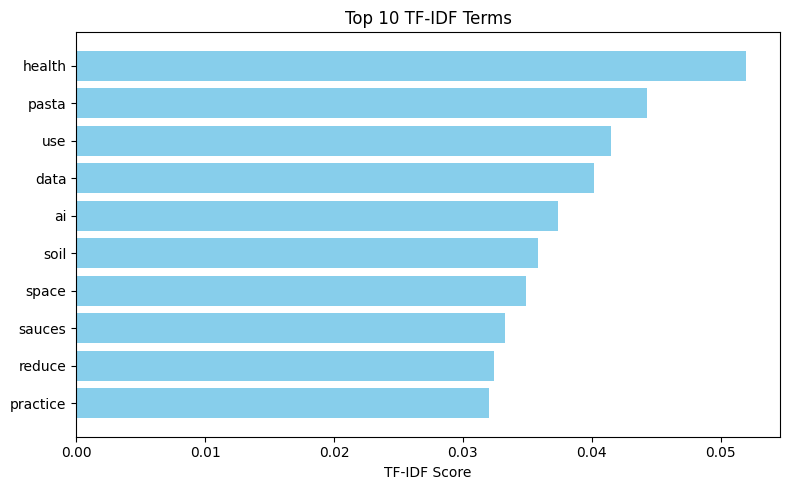

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

# Note: Ensure 'data/sample_docs.csv' exists or adjust the path as needed.
try:
    df = pd.read_csv('data/sample_docs.csv')

    vectorizer = TfidfVectorizer(stop_words='english')
    X = vectorizer.fit_transform(df['text'])
    feature_names = vectorizer.get_feature_names_out()

    # Average TF-IDF across all documents
    avg_scores = X.mean(axis=0).A1
    top_indices = avg_scores.argsort()[-10:][::-1]
    top_terms = [feature_names[i] for i in top_indices]
    top_values = avg_scores[top_indices]

    plt.figure(figsize=(8, 5))
    plt.barh(top_terms[::-1], top_values[::-1], color='skyblue')
    plt.xlabel('TF-IDF Score')
    plt.title('Top 10 TF-IDF Terms')
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    # Fallback to repository data path if structured differently
    import os
    alternative_path = '/content/unstructuredata_tfidf_repo/data/sample_docs.csv'
    if os.path.exists(alternative_path):
        df = pd.read_csv(alternative_path)
        vectorizer = TfidfVectorizer(stop_words='english')
        X = vectorizer.fit_transform(df['text'])
        feature_names = vectorizer.get_feature_names_out()
        avg_scores = X.mean(axis=0).A1
        top_indices = avg_scores.argsort()[-10:][::-1]
        top_terms = [feature_names[i] for i in top_indices]
        top_values = avg_scores[top_indices]
        plt.figure(figsize=(8, 5))
        plt.barh(top_terms[::-1], top_values[::-1], color='skyblue')
        plt.xlabel('TF-IDF Score')
        plt.title('Top 10 TF-IDF Terms')
        plt.tight_layout()
        plt.show()
    else:
        print("Please verify that 'data/sample_docs.csv' exists in your working directory.")